In [1]:
import pandas as pd
import os

# Loading the data

### CM protocols:

   ASVspoof2019_LA_cm_protocols contains protocol files in ASCII format for ASVspoof countermeasures:

   ASVspoof2019.LA.cm.train.trn.txt: training file list
   ASVspoof2019.LA.cm.dev.trl.txt: development trials
   ASVspoof2019.LA.cm.eval.trl.txt: evaluation trials 
	
   Each column of the protocol is formatted as:
   
   **SPEAKER_ID AUDIO_FILE_NAME - SYSTEM_ID KEY**

   1. **SPEAKER_ID**: 		LA_****, a 4-digit speaker ID
   2. **AUDIO_FILE_NAME**: 	LA_****, name of the audio file
   3. **SYSTEM_ID**: 		ID of the speech spoofing system (A01 - A19),  or, for bonafide speech SYSTEM-ID is left blank ('-')
   4. **-**: 			This column is NOT used for LA.
5. **KEY**: 		'bonafide' for genuine speech, or, 'spoof' for spoofing speech

Note that: 
   
1. the third column is left blank (-) to make the structure coherent with physical access file list;
2. Brief description on LA spoofing systems, where TTS and VC denote text-to-speech and voice-conversion systems:
   	

* A01	TTS	neural waveform model
* A02	TTS	vocoder
* A03	TTS	vocoder
* A04	TTS	waveform concatenation
* A05	VC	vocoder
* A06	VC	spectral filtering
        		
* A07	TTS	vocoder+GAN
* A08	TTS	neural waveform
* A09	TTS	vocoder
* A10	TTS	neural waveform
* A11	TTS	griffin lim
* A12	TTS	neural waveform
* A13	TTS_VC	waveform concatenation+waveform filtering
* A14	TTS_VC	vocoder
* A15	TTS_VC	neural waveform
* A16	TTS	waveform concatenation
* A17	VC	waveform filtering
* A18	VC	vocoder
* A19	VC	spectral filtering

In [4]:
base_path = "./data/LA"
train_protocol_path = os.path.join(base_path, "ASVspoof2019_LA_cm_protocols", "ASVspoof2019.LA.cm.train.trn.txt")
train_audio_folder = os.path.join(base_path, "ASVspoof2019_LA_train", "flac")

# collumns based on the README of the original dataset
columns = ["speaker_id", "audio_file_name", "ignored", "system_id", "label"]

df_train = pd.read_csv(train_protocol_path, sep=" ", header=None, names=columns)

df_train = df_train.drop(columns=["ignored"])


df_train['file_path'] = df_train['audio_file_name'].apply(lambda x: os.path.join(train_audio_folder, x + ".flac"))

display(df_train.head(10))
print('----------------------------------------------------------------------------------------')
df_train.tail(10)

,speaker_id,audio_file_name,system_id,label,file_path
0,LA_0079,LA_T_1138215,-,bonafide,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1138...
1,LA_0079,LA_T_1271820,-,bonafide,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1271...
2,LA_0079,LA_T_1272637,-,bonafide,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1272...
3,LA_0079,LA_T_1276960,-,bonafide,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1276...
4,LA_0079,LA_T_1341447,-,bonafide,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1341...
5,LA_0079,LA_T_1363611,-,bonafide,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1363...
6,LA_0079,LA_T_1596451,-,bonafide,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1596...
7,LA_0079,LA_T_1608170,-,bonafide,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1608...
8,LA_0079,LA_T_1684951,-,bonafide,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1684...
9,LA_0079,LA_T_1699801,-,bonafide,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1699...


----------------------------------------------------------------------------------------


,speaker_id,audio_file_name,system_id,label,file_path
25370,LA_0098,LA_T_9413366,A06,spoof,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9413...
25371,LA_0098,LA_T_9506621,A06,spoof,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9506...
25372,LA_0098,LA_T_9550569,A06,spoof,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9550...
25373,LA_0098,LA_T_9582904,A06,spoof,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9582...
25374,LA_0098,LA_T_9623506,A06,spoof,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9623...
25375,LA_0098,LA_T_9717580,A06,spoof,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9717...
25376,LA_0098,LA_T_9779814,A06,spoof,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9779...
25377,LA_0098,LA_T_9783312,A06,spoof,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9783...
25378,LA_0098,LA_T_9839348,A06,spoof,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9839...
25379,LA_0098,LA_T_9982036,A06,spoof,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9982...


# Data cleaning

1. Mapping the label to:
   
0 -> bonafide

1 -> spoofed

2. Removing the `audio_file_name` collumn since the file path already contains the name of the file.

3. Running a check to see if all of the files exist on disk

In [5]:
df_train['label'] = df_train['label'].map({'bonafide': 0, 'spoof': 1})

df_train = df_train.drop(columns=['audio_file_name'])


df_train['file_exists'] = df_train['file_path'].apply(os.path.exists)
print(f"Missing files: {len(df_train[df_train['file_exists'] == False])}")
df_train.sample(10)

Missing files: 0


,speaker_id,system_id,label,file_path,file_exists
1182,LA_0088,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_2560...,True
7594,LA_0085,A02,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_4881...,True
15976,LA_0089,A04,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_6248...,True
19219,LA_0086,A05,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_6307...,True
18913,LA_0084,A05,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9858...,True
8479,LA_0090,A02,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1772...,True
14720,LA_0082,A04,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9234...,True
16746,LA_0093,A04,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_6437...,True
18216,LA_0081,A05,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_4196...,True
18653,LA_0083,A05,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_6807...,True


In [6]:
df_train = df_train.drop(columns=['file_exists'])

In [7]:
df_train.sample(10)

,speaker_id,system_id,label,file_path
622,LA_0083,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_8387...
524,LA_0083,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1785...
21715,LA_0079,A06,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_7174...
2969,LA_0081,A01,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_2034...
1630,LA_0091,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_7583...
823,LA_0085,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_4925...
20928,LA_0095,A05,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_6497...
3596,LA_0084,A01,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_4183...
16845,LA_0094,A04,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1957...
23878,LA_0091,A06,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_2931...


4. Checking if we have unbalanced data, which we do.

In [8]:
df_train[df_train["label"] == 0].value_counts(dropna = False)

speaker_id  system_id  label  file_path                                             
LA_0079     -          0      ./data/LA/ASVspoof2019_LA_train/flac/LA_T_1138215.flac    1
                              ./data/LA/ASVspoof2019_LA_train/flac/LA_T_1271820.flac    1
                              ./data/LA/ASVspoof2019_LA_train/flac/LA_T_1272637.flac    1
                              ./data/LA/ASVspoof2019_LA_train/flac/LA_T_1276960.flac    1
                              ./data/LA/ASVspoof2019_LA_train/flac/LA_T_1341447.flac    1
                                                                                       ..
LA_0098     -          0      ./data/LA/ASVspoof2019_LA_train/flac/LA_T_9387015.flac    1
                              ./data/LA/ASVspoof2019_LA_train/flac/LA_T_9497115.flac    1
                              ./data/LA/ASVspoof2019_LA_train/flac/LA_T_9557645.flac    1
                              ./data/LA/ASVspoof2019_LA_train/flac/LA_T_9737995.flac    1
               

In [9]:
df_train[df_train["label"] == 1].value_counts(dropna = False)

speaker_id  system_id  label  file_path                                             
LA_0079     A01        1      ./data/LA/ASVspoof2019_LA_train/flac/LA_T_1004644.flac    1
                              ./data/LA/ASVspoof2019_LA_train/flac/LA_T_1056709.flac    1
                              ./data/LA/ASVspoof2019_LA_train/flac/LA_T_1195221.flac    1
                              ./data/LA/ASVspoof2019_LA_train/flac/LA_T_1265032.flac    1
                              ./data/LA/ASVspoof2019_LA_train/flac/LA_T_1287124.flac    1
                                                                                       ..
LA_0098     A06        1      ./data/LA/ASVspoof2019_LA_train/flac/LA_T_9717580.flac    1
                              ./data/LA/ASVspoof2019_LA_train/flac/LA_T_9779814.flac    1
                              ./data/LA/ASVspoof2019_LA_train/flac/LA_T_9783312.flac    1
                              ./data/LA/ASVspoof2019_LA_train/flac/LA_T_9839348.flac    1
               

* Downsampling the dataset from 22800 to 7500 spoofed audios for performance and for class balancing

In [13]:

df_real = df_train[df_train['label'] == 0]
df_fake = df_train[df_train['label'] == 1]


df_fake_sampled = df_fake.sample(n=7500, random_state=42)


df_train_downsampled = pd.concat([df_real, df_fake_sampled])


df_train_downsampled = df_train_downsampled.sample(frac=1, random_state=42).reset_index(drop=True)


print("New Class Distribution:")
print(df_train_downsampled['label'].value_counts())

New Class Distribution:
label
1    7500
0    2580
Name: count, dtype: int64


In [16]:
#df_train = df_train_balanced
print(df_train['label'].value_counts())
df_train.sample(10)

label
1    22800
0     2580
Name: count, dtype: int64


,speaker_id,system_id,label,file_path
24399,LA_0093,A06,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9297...
4086,LA_0086,A01,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9867...
16663,LA_0093,A04,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_2391...
9732,LA_0096,A02,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_6788...
22372,LA_0083,A06,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_2729...
10410,LA_0080,A03,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_3147...
1233,LA_0088,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_7220...
1422,LA_0090,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1511...
5648,LA_0095,A01,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_2703...
1467,LA_0090,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_5654...


In [17]:
display(df_train.head(5))
df_train.tail(5)

,speaker_id,system_id,label,file_path
0,LA_0079,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1138...
1,LA_0079,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1271...
2,LA_0079,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1272...
3,LA_0079,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1276...
4,LA_0079,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1341...


,speaker_id,system_id,label,file_path
25375,LA_0098,A06,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9717...
25376,LA_0098,A06,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9779...
25377,LA_0098,A06,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9783...
25378,LA_0098,A06,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9839...
25379,LA_0098,A06,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9982...


# Generating the spectograms

The `generate_mel_spectogram` function will take a .flac file path and generate a mel spectogram based on that audio, truncated/padded to 4 seconds long, using a sampling rate of 16 kHz as specified in the README of the dataset.

In [15]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

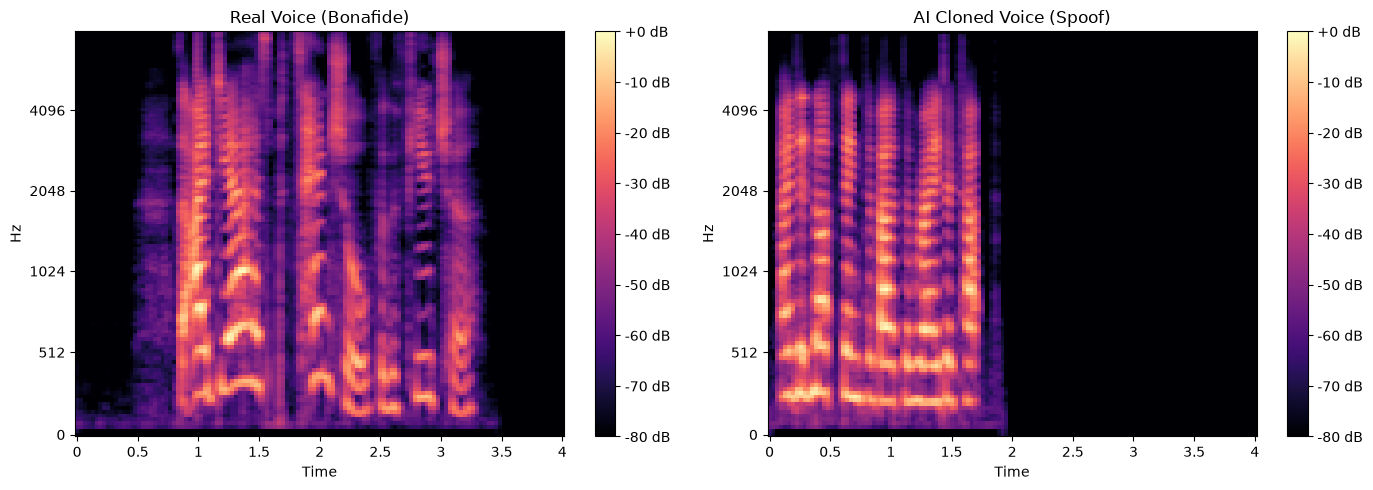

In [18]:
def generate_mel_spectrogram(file_path, target_seconds=4, sample_rate=16000):
    
    target_length = target_seconds * sample_rate
    
    
    y, sr = librosa.load(file_path, sr=sample_rate)
    
    
    y_fixed = librosa.util.fix_length(data=y, size=target_length)
    
    
    mel_spec = librosa.feature.melspectrogram(y=y_fixed, sr=sr, n_mels=128)
    
    
    mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
    
    return mel_spec_db


sample_real_path = df_train[df_train['label'] == 0].iloc[0]['file_path']
sample_fake_path = df_train[df_train['label'] == 1].iloc[0]['file_path']


spec_real = generate_mel_spectrogram(sample_real_path)
spec_fake = generate_mel_spectrogram(sample_fake_path)


fig, ax = plt.subplots(1, 2, figsize=(14, 5))

img1 = librosa.display.specshow(spec_real, sr=16000, x_axis='time', y_axis='mel', ax=ax[0])
ax[0].set_title('Real Voice (Bonafide)')
fig.colorbar(img1, ax=ax[0], format='%+2.0f dB')

img2 = librosa.display.specshow(spec_fake, sr=16000, x_axis='time', y_axis='mel', ax=ax[1])
ax[1].set_title('AI Cloned Voice (Spoof)')
fig.colorbar(img2, ax=ax[1], format='%+2.0f dB')

plt.tight_layout()
plt.show()

In [20]:
from tqdm import tqdm

In [21]:
df_train_img = df_train.copy()
df_train_img.sample(10)

,speaker_id,system_id,label,file_path
2115,LA_0095,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_5011...
13384,LA_0095,A03,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_8745...
12002,LA_0088,A03,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_7661...
20526,LA_0093,A05,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_5525...
3116,LA_0081,A01,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_8950...
24972,LA_0096,A06,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_8612...
21223,LA_0097,A05,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1949...
25313,LA_0098,A06,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_6838...
13906,LA_0098,A03,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_6232...
21943,LA_0080,A06,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9619...


Generating a mel spectogram for each .flac audio file and exporting them to disk. Images are separated in spoofed and bonafide directories based on their label.

In [22]:

output_base_dir = "./data/dataset_img/train"

def compute_img_path(row):
    subfolder = "bonafide" if row['label'] == 0 else "spoofed"
    return os.path.join(output_base_dir, subfolder, f"sample_{row.name}.png")


df_train_img['img_path'] = df_train_img.apply(compute_img_path, axis=1)

os.makedirs(os.path.join(output_base_dir, "bonafide"), exist_ok=True)
os.makedirs(os.path.join(output_base_dir, "spoofed"), exist_ok=True)

print("Starting Mel-spectrogram export to disk...")


for idx, row in tqdm(df_train.iterrows(), total=len(df_train)):
    file_path = row['file_path']
    label = row['label']
    
    try:
        
        spec_db = generate_mel_spectrogram(file_path)
        
        
        if label == 0:
            dest_folder = os.path.join(output_base_dir, "bonafide")
        else:
            dest_folder = os.path.join(output_base_dir, "spoofed")
            
        
        img_filename = f"sample_{idx}.png"
        img_path = os.path.join(dest_folder, img_filename)
        
        
        plt.imsave(img_path, spec_db, cmap='magma', origin='lower')
        
    except Exception as e:
        print(f"Error processing index {idx} ({file_path}): {e}")
        continue

print(f"Export complete! Check your directory: {output_base_dir}")

Starting Mel-spectrogram export to disk...


100%|██████████████████████████████████████████████████| 25380/25380 [04:58<00:00, 85.14it/s]

Export complete! Check your directory: ./data/dataset_img/train


In [23]:
df_train_img

,speaker_id,system_id,label,file_path,img_path
0,LA_0079,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1138...,./data/dataset_img/train/bonafide/sample_0.png
1,LA_0079,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1271...,./data/dataset_img/train/bonafide/sample_1.png
2,LA_0079,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1272...,./data/dataset_img/train/bonafide/sample_2.png
3,LA_0079,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1276...,./data/dataset_img/train/bonafide/sample_3.png
4,LA_0079,-,0,./data/LA/ASVspoof2019_LA_train/flac/LA_T_1341...,./data/dataset_img/train/bonafide/sample_4.png
...,...,...,...,...,...
25375,LA_0098,A06,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9717...,./data/dataset_img/train/spoofed/sample_25375.png
25376,LA_0098,A06,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9779...,./data/dataset_img/train/spoofed/sample_25376.png
25377,LA_0098,A06,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9783...,./data/dataset_img/train/spoofed/sample_25377.png
25378,LA_0098,A06,1,./data/LA/ASVspoof2019_LA_train/flac/LA_T_9839...,./data/dataset_img/train/spoofed/sample_25378.png


Preparing the image dataset for exporting

In [24]:
df_export = df_train_img.drop(columns = ['file_path'])
df_export

,speaker_id,system_id,label,img_path
0,LA_0079,-,0,./data/dataset_img/train/bonafide/sample_0.png
1,LA_0079,-,0,./data/dataset_img/train/bonafide/sample_1.png
2,LA_0079,-,0,./data/dataset_img/train/bonafide/sample_2.png
3,LA_0079,-,0,./data/dataset_img/train/bonafide/sample_3.png
4,LA_0079,-,0,./data/dataset_img/train/bonafide/sample_4.png
...,...,...,...,...
25375,LA_0098,A06,1,./data/dataset_img/train/spoofed/sample_25375.png
25376,LA_0098,A06,1,./data/dataset_img/train/spoofed/sample_25376.png
25377,LA_0098,A06,1,./data/dataset_img/train/spoofed/sample_25377.png
25378,LA_0098,A06,1,./data/dataset_img/train/spoofed/sample_25378.png


Exporting the image dataset to csv

In [28]:
df_export.to_csv("./data/dataset_img/train/metadata_train.csv", index = False)